# Experiment 2: Text Retrieval

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Connect to a Twitter account and extract the first 100 tweets from it into a file.
2. Study and implementation of text processing: word and sentence tokenization.

## Step 1: Install and import the required packages

In [9]:
%pip install tweepy nltk pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import os
import pandas as pd
import tweepy
import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("twitter_samples", quiet=True)

True

### Chart style

In [11]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

# Part 1: Connect to Twitter and extract 100 tweets

Twitter (X) is accessed through its official **API v2** with a **Bearer Token** from [developer.x.com](https://developer.x.com). `tweepy.Client` connects with the token, `get_user()` finds the account, and `get_users_tweets()` returns up to 100 of its latest tweets in one request. The token is read from the `TWITTER_BEARER_TOKEN` environment variable so it isn't stored in the notebook.

If no token is set (or the API refuses the request), the code uses NLTK's `twitter_samples` corpus, which contains real tweets collected through the Twitter API.

In [12]:
BEARER_TOKEN = os.environ.get("TWITTER_BEARER_TOKEN", "")
USERNAME = "NASA"
N_TWEETS = 100


def fetch_from_twitter(username, n, token):
    client = tweepy.Client(bearer_token=token)
    user = client.get_user(username=username).data
    print(f"Connected to @{user.username}")
    resp = client.get_users_tweets(id=user.id, max_results=min(n, 100), tweet_fields=["created_at"])
    return pd.DataFrame([{"tweet_id": t.id, "created_at": t.created_at, "user": username, "text": t.text}
                         for t in resp.data or []])


def fetch_from_nltk(n):
    from nltk.corpus import twitter_samples
    raw = twitter_samples.docs("tweets.20150430-223406.json")[:n]
    return pd.DataFrame([{"tweet_id": t["id"], "created_at": t["created_at"],
                          "user": t["user"]["screen_name"], "text": t["text"]} for t in raw])


try:
    if not BEARER_TOKEN:
        raise ValueError("TWITTER_BEARER_TOKEN is not set")
    tweets = fetch_from_twitter(USERNAME, N_TWEETS, BEARER_TOKEN)
except Exception as e:
    print("Twitter API not used:", e)
    print("Using the NLTK twitter_samples corpus instead.")
    tweets = fetch_from_nltk(N_TWEETS)

tweets.to_csv("tweets.csv", index=False, encoding="utf-8")
print(f"Saved {len(tweets)} tweets to 'tweets.csv'")
pd.read_csv("tweets.csv")[["user", "text"]].head(10)

Twitter API not used: TWITTER_BEARER_TOKEN is not set
Using the NLTK twitter_samples corpus instead.
Saved 100 tweets to 'tweets.csv'


,user,text
0,vienesewaltz,RT @KirkKus: Indirect cost of the UK being in ...
1,RaymondDJones1,VIDEO: Sturgeon on post-election deals http://...
2,katebrownbill28,RT @LabourEoin: The economy was growing 3 time...
3,rachiirobbo,RT @GregLauder: the UKIP east lothian candidat...
4,stuyha,RT @thesundaypeople: UKIP's housing spokesman ...
5,Graeme__McGuire,RT @Nigel_Farage: Make sure you tune in to #As...
6,moosehead49,RT @joannetallis: Ed Milliband is an embarrass...
7,GallahersBlues,RT @abstex: The FT is backing the Tories. On a...
8,richarding,RT @NivenJ1: “@George_Osborne: Ed Miliband pro...
9,MaraBellaNature,LOLZ to Trickle Down Wealth. It's never trickl...


# Part 2: Word and sentence tokenization

**Tokenization** splits text into smaller units called tokens.
- **Sentence tokenization** splits text into sentences. Splitting on `.` fails on abbreviations (*Dr.*, *U.S.*) and decimals (*3.5*); NLTK's `sent_tokenize` uses the trained **Punkt** model to find real sentence ends.
- **Word tokenization** splits a sentence into words and punctuation. Different tokenizers follow different rules.

## 2.1 Sentence tokenization

In [13]:
from nltk.tokenize import sent_tokenize

paragraph = ("Dr. Smith moved to the U.S. in 2019. She now works at NASA as a data scientist! "
             "Her team's budget grew by 3.5 million dollars. Isn't that amazing? "
             "Natural Language Processing (NLP) helps computers understand human language.")

naive = [s.strip() for s in paragraph.split(".") if s.strip()]
sentences = sent_tokenize(paragraph)

print("Naive split on '.':", len(naive), "pieces")
for s in naive:
    print("  -", s)
print()
print("sent_tokenize:", len(sentences), "sentences")
for i, s in enumerate(sentences, 1):
    print(f"  {i}. {s}")

Naive split on '.': 7 pieces
  - Dr
  - Smith moved to the U
  - S
  - in 2019
  - She now works at NASA as a data scientist! Her team's budget grew by 3
  - 5 million dollars
  - Isn't that amazing? Natural Language Processing (NLP) helps computers understand human language

sent_tokenize: 5 sentences
  1. Dr. Smith moved to the U.S. in 2019.
  2. She now works at NASA as a data scientist!
  3. Her team's budget grew by 3.5 million dollars.
  4. Isn't that amazing?
  5. Natural Language Processing (NLP) helps computers understand human language.


## 2.2 Word tokenization

In [14]:
from nltk.tokenize import word_tokenize, TweetTokenizer, WordPunctTokenizer, RegexpTokenizer

text = "I can't believe it's already 2026!! Email me at test@mail.com :) #NLP @OpenAI"

methods = {
    "str.split()":           text.split(),
    "word_tokenize":         word_tokenize(text),
    "WordPunctTokenizer":    WordPunctTokenizer().tokenize(text),
    "RegexpTokenizer(\\w+)": RegexpTokenizer(r"\w+").tokenize(text),
    "TweetTokenizer":        TweetTokenizer().tokenize(text),
}
for name, toks in methods.items():
    print(f"{name:<22} ({len(toks):>2} tokens): {toks}")

str.split()            (13 tokens): ['I', "can't", 'believe', "it's", 'already', '2026!!', 'Email', 'me', 'at', 'test@mail.com', ':)', '#NLP', '@OpenAI']
word_tokenize          (22 tokens): ['I', 'ca', "n't", 'believe', 'it', "'s", 'already', '2026', '!', '!', 'Email', 'me', 'at', 'test', '@', 'mail.com', ':', ')', '#', 'NLP', '@', 'OpenAI']
WordPunctTokenizer     (24 tokens): ['I', 'can', "'", 't', 'believe', 'it', "'", 's', 'already', '2026', '!!', 'Email', 'me', 'at', 'test', '@', 'mail', '.', 'com', ':)', '#', 'NLP', '@', 'OpenAI']
RegexpTokenizer(\w+)   (16 tokens): ['I', 'can', 't', 'believe', 'it', 's', 'already', '2026', 'Email', 'me', 'at', 'test', 'mail', 'com', 'NLP', 'OpenAI']
TweetTokenizer         (15 tokens): ['I', "can't", 'believe', "it's", 'already', '2026', '!', '!', 'Email', 'me', 'at', 'test@mail.com', ':)', '#NLP', '@OpenAI']


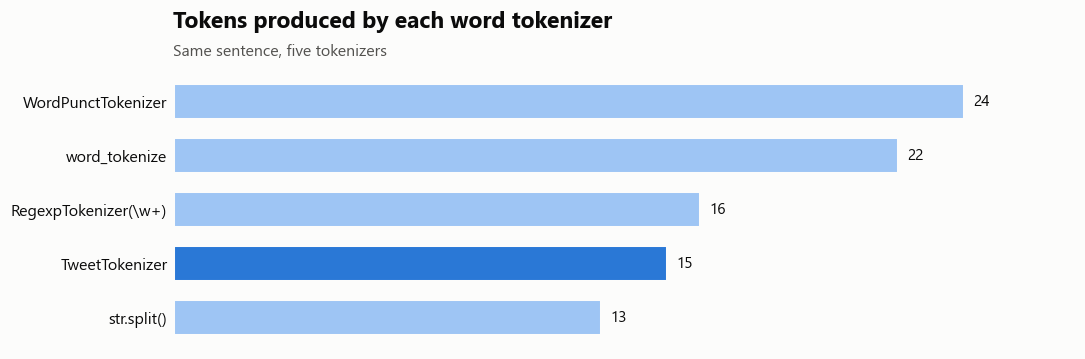

In [15]:
counts = pd.Series({k: len(v) for k, v in methods.items()}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.4))
hbar(ax, counts.index, counts.values, color=BLUE_LIGHT, highlight="TweetTokenizer")
titles(ax, "Tokens produced by each word tokenizer", "Same sentence, five tokenizers")
plt.tight_layout()
plt.show()

- `str.split()` splits only on spaces, so punctuation stays attached (`2026!!`).
- `word_tokenize` splits contractions (`ca` + `n't`) but breaks `#NLP`, `@OpenAI` and `:)` apart.
- `WordPunctTokenizer` splits at every punctuation mark, breaking the email address.
- `RegexpTokenizer(\w+)` keeps only letters and digits.
- `TweetTokenizer` keeps hashtags, mentions and emoticons whole, so it suits tweets best.

## 2.3 Tokenizing the extracted tweets

In [16]:
tweet_tok = TweetTokenizer()
tweets["sentences"] = tweets["text"].apply(sent_tokenize)
tweets["words"] = tweets["text"].apply(tweet_tok.tokenize)

for i in range(3):
    print(f"Tweet {i + 1}: {tweets['text'][i]}")
    print("  Sentences:", tweets["sentences"][i])
    print("  Words    :", tweets["words"][i])
    print()

print("Total sentences:", tweets["sentences"].str.len().sum())
print("Total word tokens:", tweets["words"].str.len().sum())

Tweet 1: RT @KirkKus: Indirect cost of the UK being in the EU is estimated to be costing Britain £170 billion per year! #BetterOffOut #UKIP
  Sentences: ['RT @KirkKus: Indirect cost of the UK being in the EU is estimated to be costing Britain £170 billion per year!', '#BetterOffOut #UKIP']
  Words    : ['RT', '@KirkKus', ':', 'Indirect', 'cost', 'of', 'the', 'UK', 'being', 'in', 'the', 'EU', 'is', 'estimated', 'to', 'be', 'costing', 'Britain', '£', '170', 'billion', 'per', 'year', '!', '#BetterOffOut', '#UKIP']

Tweet 2: VIDEO: Sturgeon on post-election deals http://t.co/BTJwrpbmOY
  Sentences: ['VIDEO: Sturgeon on post-election deals http://t.co/BTJwrpbmOY']
  Words    : ['VIDEO', ':', 'Sturgeon', 'on', 'post-election', 'deals', 'http://t.co/BTJwrpbmOY']

Tweet 3: RT @LabourEoin: The economy was growing 3 times faster on the day David Cameron became Prime Minister than it is today.. #BBCqt http://t.co…
  Sentences: ['RT @LabourEoin: The economy was growing 3 times faster on the day Da

## Conclusion
We connected to Twitter through the X API v2 with `tweepy` (falling back to NLTK's real tweet corpus when no token is available) and saved 100 tweets to `tweets.csv`. We then implemented sentence tokenization with Punkt, which handles abbreviations and decimals correctly, compared five word tokenizers, and applied sentence and word tokenization to the extracted tweets using `TweetTokenizer`, which keeps hashtags, mentions and emoticons intact.